# P05B — Evaluasi dan pemeriksaan model

Jalankan P05A terlebih dahulu dan gunakan folder kerja yang sama. Notebook ini menghitung metrik regresi/klasifikasi/clustering serta melakukan pemeriksaan global, subset, kasus dan ketidakpastian. Evaluasi ini ilustrasi pedagogis, bukan sertifikasi desain atau keselamatan.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GroupShuffleSplit, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score, confusion_matrix, precision_score, recall_score, balanced_accuracy_score, roc_auc_score, silhouette_score, adjusted_rand_score)
from sklearn.cluster import KMeans
SEED = 51505
rng = np.random.default_rng(SEED)
data_dir = next((p for p in [Path("praktikum/bab05/data_bab5"), Path("data_bab5")] if p.is_dir()), None)
if data_dir is None:
    raise FileNotFoundError("Folder data_bab5 tidak ditemukan. Jalankan P05A terlebih dahulu pada folder kerja yang sama.")
beam = pd.read_csv(data_dir / "data_sintesis_lendutan.csv")
bridge = pd.read_csv(data_dir / "data_sintesis_prioritas.csv")
cluster_data = pd.read_csv(data_dir / "data_sintesis_cluster.csv")
print("Lendutan", beam.shape, "balok", beam.beam_id.nunique())
print("Prioritas", bridge.priority_label.value_counts().to_dict())
print("Cluster", cluster_data.shape)


Lendutan (1296, 6) balok 72
Prioritas {'prioritas': 1150, 'rutin': 50}
Cluster (700, 6)


## 1. Memuat data dan memahami unit evaluasi

Setiap baris adalah satu tahap pembebanan; banyak baris berasal dari balok yang sama. Pembagian evaluasi menahan balok utuh agar prediksi pada balok baru tidak dinilai dari tahap pembebanan yang berkaitan dengan data latih.

## 2. Regresi: residual dan metrik pelengkap

In [2]:
features = ["span_m", "reinforcement_ratio", "temperature_C", "load_kN"]
X = beam[features]
y = beam["deflection_mm"]
groups = beam["beam_id"]
splitter = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=SEED)
train_idx, test_idx = next(splitter.split(X, y, groups))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
beam_test = beam.iloc[test_idx].copy()
models = {"baseline_rerata": DummyRegressor(),
          "linear": LinearRegression(),
          "random_forest": RandomForestRegressor(n_estimators=250, min_samples_leaf=3, random_state=SEED)}
predictions, summary = {}, []
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    predictions[name] = pred
    resid = y_test.to_numpy() - pred
    summary.append({"model": name, "ME_mm": resid.mean(),
        "MAE_mm": mean_absolute_error(y_test, pred),
        "RMSE_mm": mean_squared_error(y_test, pred)**0.5,
        "R2": r2_score(y_test, pred)})
pd.DataFrame(summary).round(3)

,model,ME_mm,MAE_mm,RMSE_mm,R2
0,baseline_rerata,-0.181,27.456,33.598,-0.000
1,linear,-0.676,8.197,10.809,0.896
2,random_forest,0.084,3.498,4.924,0.979


Residual positif berarti prediksi lebih rendah daripada pengamatan karena residual didefinisikan sebagai aktual dikurangi prediksi. MAE, RMSE, ME, dan R² menjawab aspek yang berbeda.

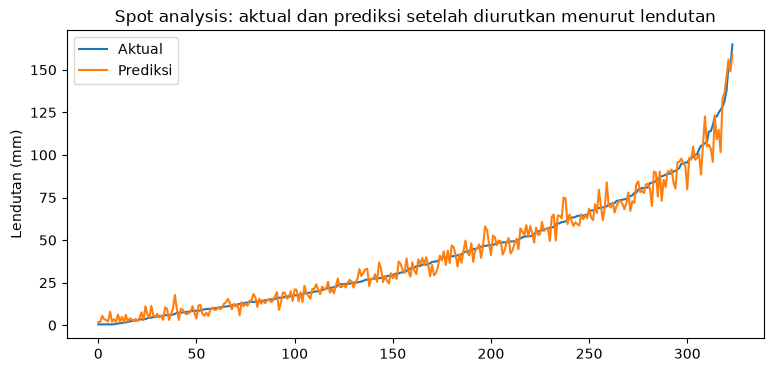

In [3]:
name = "random_forest"
y_pred = predictions[name]
residual = y_test.to_numpy() - y_pred
spot = pd.DataFrame({"actual": y_test.to_numpy(), "predicted": y_pred, "residual": residual})
spot = spot.sort_values("actual")
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(spot["actual"].to_numpy(), label="Aktual")
ax.plot(spot["predicted"].to_numpy(), label="Prediksi")
ax.set_title("Spot analysis: aktual dan prediksi setelah diurutkan menurut lendutan")
ax.set_ylabel("Lendutan (mm)"); ax.legend(); plt.show()

## 3. Kinerja subset dan kasus individual

In [4]:
threshold = 100.0
subset = y_test.to_numpy() >= threshold
print("Jumlah kasus ≥ 100 mm:", int(subset.sum()))
if subset.any():
    print("MAE subset ekstrem (mm):", mean_absolute_error(y_test.to_numpy()[subset], y_pred[subset]))

beam_test["predicted_mm"] = y_pred
beam_test["residual_mm"] = beam_test["deflection_mm"] - beam_test["predicted_mm"]
beam_test.groupby("beam_id")["residual_mm"].agg(["count", "mean", "median", "max"]).head()

Jumlah kasus ≥ 100 mm: 20
MAE subset ekstrem (mm): 8.14007564007321


,count,mean,median,max
beam_id,,,,
B002,18,-3.307648,-2.599775,2.108444
B005,18,0.178391,-0.633255,10.454685
B007,18,-3.775199,-3.707935,2.889746
B013,18,-0.009679,0.406294,6.683859
B015,18,2.748605,2.312655,13.749209


Subset ekstrem hanya contoh audit; ambang harus ditetapkan dari kebutuhan rekayasa, bukan dipilih setelah melihat model. Periksa juga kurva per balok untuk menemukan pola yang tidak tampak pada tabel ringkasan.

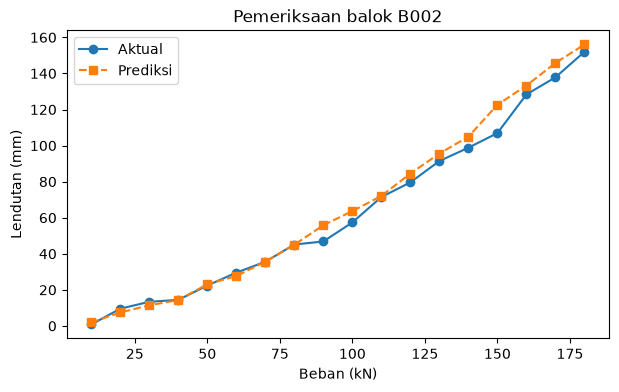

In [5]:
example_beam = beam_test["beam_id"].iloc[0]
one = beam_test[beam_test["beam_id"] == example_beam].sort_values("load_kN")
plt.figure(figsize=(7, 4))
plt.plot(one["load_kN"], one["deflection_mm"], "o-", label="Aktual")
plt.plot(one["load_kN"], one["predicted_mm"], "s--", label="Prediksi")
plt.xlabel("Beban (kN)"); plt.ylabel("Lendutan (mm)"); plt.title(f"Pemeriksaan balok {example_beam}"); plt.legend(); plt.show()

## 4. Indikator fungsional dan pemeriksaan rasional

Kerja eksternal pada kurva beban–lendutan dihitung sebagai integral beban terhadap perubahan lendutan, ∫P dδ. Pada latihan ini kN·mm setara J. Asumsi lintasan dan batas fisik tetap perlu diperiksa; nilai energi bukan pengganti inspeksi bentuk kurva.

In [6]:
# Kerja eksternal sepanjang lintasan pembebanan: integral P d(delta).
path = one.sort_values("load_kN")
actual_work = np.trapezoid(path["load_kN"], path["deflection_mm"])
pred_work = np.trapezoid(path["load_kN"], path["predicted_mm"])
print("Kerja aktual pada lintasan (kN·mm = J):", round(actual_work, 2))
print("Kerja menurut prediksi (kN·mm = J):", round(pred_work, 2))
print("Penurunan lendutan prediksi ketika beban naik:", int((np.diff(path["predicted_mm"]) < 0).sum()))


Kerja aktual pada lintasan (kN·mm = J): 16702.91
Kerja menurut prediksi (kN·mm = J): 16848.27
Penurunan lendutan prediksi ketika beban naik: 0


Pemeriksaan rasional tersebut mengasumsikan beban meningkat pada balok dan kondisi tetap. Ia tidak membuktikan kausalitas atau keamanan model; validitas aturannya perlu ditinjau menurut keadaan pembebanan.

## 5. Interval bootstrap untuk metrik

In [7]:
groups_test = beam_test["beam_id"].unique()
by_group = {g: beam_test[beam_test["beam_id"] == g].index.to_numpy() for g in groups_test}
index_to_pos = {idx: pos for pos, idx in enumerate(beam_test.index)}
mae_boot = []
for _ in range(600):
    sampled = rng.choice(groups_test, size=len(groups_test), replace=True)
    pos = [index_to_pos[idx] for g in sampled for idx in by_group[g]]
    mae_boot.append(mean_absolute_error(y_test.to_numpy()[pos], y_pred[pos]))
np.quantile(mae_boot, [0.025, 0.5, 0.975])

array([2.92862373, 3.48039565, 4.23298416])

Bootstrap di atas mengulang pengambilan balok dan merangkum variasi MAE. Interval ini menyatakan ketidakpastian metrik pada sampling balok, bukan rentang lendutan untuk satu prediksi.

## 6. Klasifikasi sintesis prioritas inspeksi

In [8]:
Xc = bridge.drop(columns=["bridge_id", "priority_label"])
yc = bridge["priority_label"]
Xc_train, Xc_test, yc_train, yc_test = train_test_split(
    Xc, yc, test_size=0.25, random_state=SEED, stratify=yc)
clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, class_weight="balanced"))
clf.fit(Xc_train, yc_train)
positive = "prioritas"
prob = clf.predict_proba(Xc_test)[:, list(clf.classes_).index(positive)]
threshold = 0.5
yc_pred = np.where(prob >= threshold, positive, "rutin")
cm = confusion_matrix(yc_test, yc_pred, labels=["prioritas", "rutin"])
print("Rows actual [prioritas, rutin]; columns predicted [prioritas, rutin]\n", cm)
print("Recall prioritas:", recall_score(yc_test, yc_pred, pos_label=positive))
print("Precision prioritas:", precision_score(yc_test, yc_pred, pos_label=positive))
print("Balanced accuracy:", balanced_accuracy_score(yc_test, yc_pred))
print("ROC-AUC:", roc_auc_score((yc_test == positive).astype(int), prob))

Rows actual [prioritas, rutin]; columns predicted [prioritas, rutin]
 [[269  19]
 [  0  12]]
Recall prioritas: 0.9340277777777778
Precision prioritas: 1.0
Balanced accuracy: 0.9670138888888888
ROC-AUC: 0.9916087962962963


Threshold 0.5 bukan aturan keselamatan. Ubah ambang hanya pada data validasi dan jelaskan trade-off inspeksi tertunda versus pemeriksaan tambahan. Label sintetis pada notebook bukan keputusan inspeksi yang tervalidasi.

## 7. Clustering sintesis perkerasan

In [9]:
cluster_features = ["feature_1", "feature_2", "feature_3", "feature_4"]
Xb = cluster_data[cluster_features].to_numpy()
z = cluster_data["label_pembangkit"].to_numpy()
features_cluster = StandardScaler().fit_transform(Xb)
cluster_model = KMeans(n_clusters=4, n_init=20, random_state=SEED)
cluster_labels = cluster_model.fit_predict(features_cluster)
print("Inertia:", round(cluster_model.inertia_, 3))
print("Silhouette:", round(silhouette_score(features_cluster, cluster_labels), 3))
print("Adjusted Rand vs label pembangkit (audit latihan):", round(adjusted_rand_score(z, cluster_labels), 3))


Inertia: 100.139
Silhouette: 0.804
Adjusted Rand vs label pembangkit (audit latihan): 1.0


Silhouette mengukur pemisahan menurut representasi fitur dan jarak. Adjusted Rand pada contoh hanya mungkin karena label sintesis diketahui; pada masalah clustering tanpa label, ukuran eksternal tersebut tidak tersedia. Keduanya tidak menetapkan tindakan teknik yang tepat.

## Ringkasan batas penggunaan

Data sintesis membantu menunjukkan bagaimana metrik bereaksi terhadap kelompok, ketidakseimbangan kelas, residual ekstrem, dan struktur kurva. Jangan gunakan nilai hasil notebook sebagai ambang desain, batas keselamatan, atau bukti kinerja pada infrastruktur nyata. Catat seed, pembagian kelompok, target, satuan, dan aturan evaluasi jika notebook dikembangkan lebih lanjut.